# Where can a drone navigate magnetically in Ireland? (COH-23)

A map of Ireland showing how well magnetic navigation *can* work at each spot, worked out from
the Tellus map alone before anyone flies. Then a check of whether the filter knows when it's lost
(the **protection level**). Edit a cell and re-run it.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap
from navfilter import scenario
from navfilter.navigability import information_map, CLASSES

grid = scenario.load_map("merge_tmi")
nav = information_map(grid)              # all Ireland, a few seconds
bound, classes = nav.bound_m(), nav.classes()

surveyed = classes > 0
print("share of the surveyed area:")
for k in range(1, 5):
    print(f"   {CLASSES[k]:24s} {np.mean(classes[surveyed] == k):6.1%}")

share of the surveyed area:
   good                      18.5%
   marginal                  34.0%
   flat                      47.0%
   too rough for the map      0.4%


## 1. The map

**Left:** the best position error the map allows over a 1 km track, in metres (lower is better).
**Right:** the same thing as classes:
- **good:** under 50 m
- **marginal:** 50–250 m
- **flat:** not enough texture to navigate on
- **too rough for the map:** the 200 m map misses more than the filter allows for, so the filter will trust a wrong map

How the number is computed: it uses the weakest direction of the map's gradients, taken from the
map at the resolution the filter actually has, plus what that map gets wrong. The details are in
`navfilter/navigability.py`.

Co. Mayo demo        21 m  good
midlands            269 m  flat
A7 headline         155 m  marginal
DCU flight site    no survey here


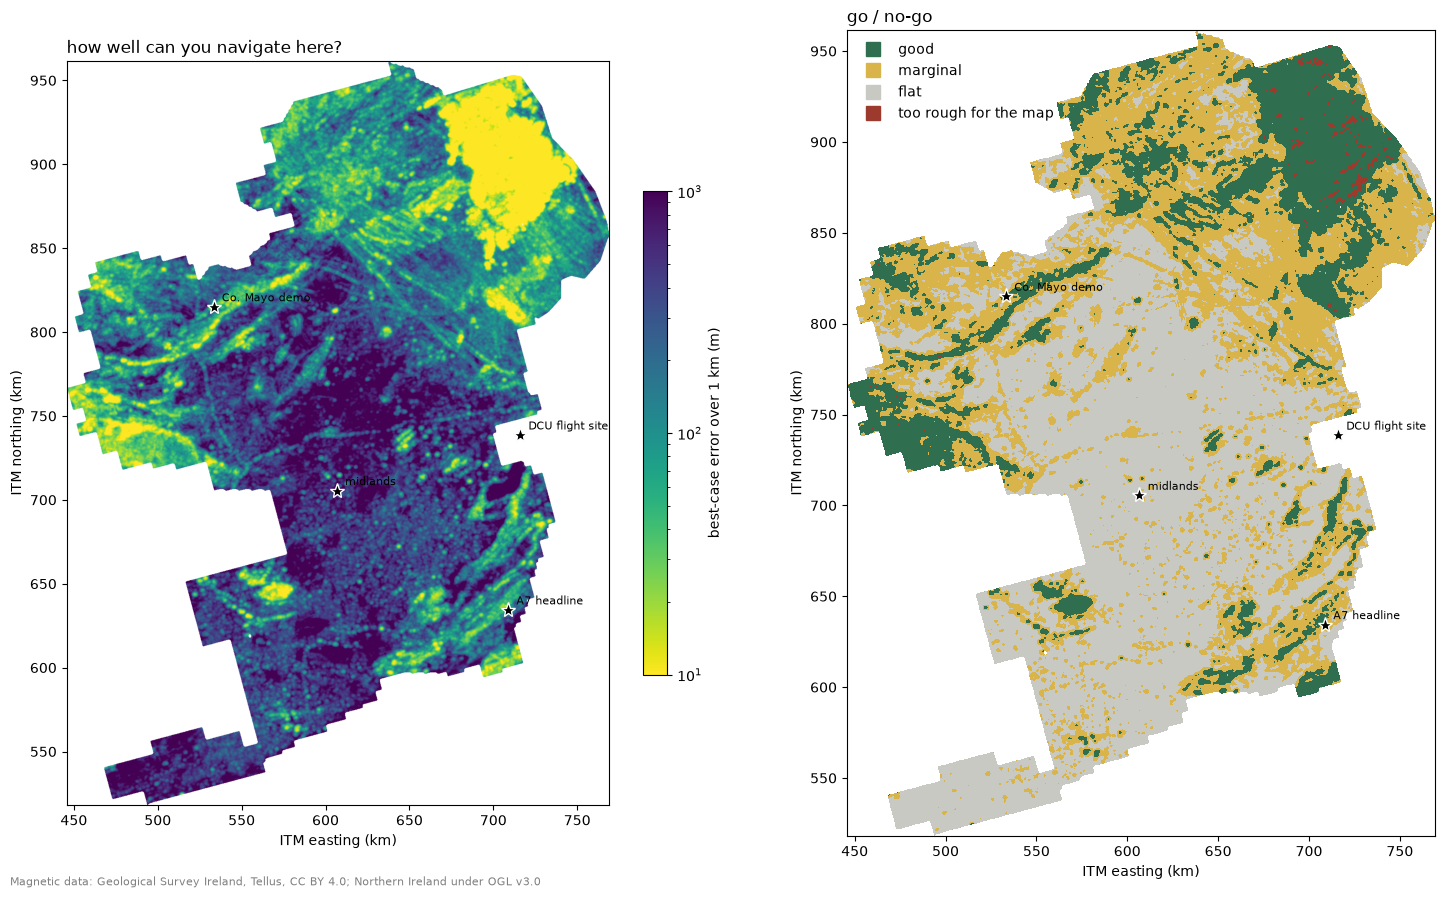

In [2]:
PLACES = {"Co. Mayo demo": (54.08, -9.02), "midlands": (53.10, -7.90),
          "A7 headline": (52.45, -6.40), "DCU flight site": (53.385, -6.257)}

left, right, bottom, top = nav.extent
km = lambda v: v / 1000
ext = (km(left), km(right), km(bottom), km(top))
class_cmap = ListedColormap(["#ffffff", "#2f6f4f", "#d9b44a", "#c9c9c4", "#9c3a2e"])

fig, ax = plt.subplots(1, 2, figsize=(15, 9))
im = ax[0].imshow(bound, extent=ext, cmap="viridis_r", norm=LogNorm(10, 1000))
fig.colorbar(im, ax=ax[0], shrink=0.6, label="best-case error over 1 km (m)")
ax[1].imshow(classes, extent=ext, cmap=class_cmap, vmin=-0.5, vmax=4.5, interpolation="nearest")
for k in range(1, 5):
    ax[1].plot([], [], "s", color=class_cmap(k), ms=10, label=CLASSES[k])
ax[1].legend(frameon=False, loc="upper left")
for a in ax:
    for name, (lat, lon) in PLACES.items():
        x, y = grid._to_grid.transform(lon, lat)
        a.plot(km(x), km(y), "k*", ms=11, mec="white")
        a.annotate(name, (km(x), km(y)), xytext=(6, 4), textcoords="offset points", fontsize=8)
    a.set_xlabel("ITM easting (km)"); a.set_ylabel("ITM northing (km)"); a.set_aspect("equal")
ax[0].set_title("how well can you navigate here?", loc="left")
ax[1].set_title("go / no-go", loc="left")
fig.text(0.01, 0.01, "Magnetic data: Geological Survey Ireland, Tellus, CC BY 4.0; "
         "Northern Ireland under OGL v3.0", color="0.5", fontsize=8)
fig.tight_layout()

for name, (lat, lon) in PLACES.items():
    b = nav.at(lat, lon)[0]; c = nav.at(lat, lon, layer=classes)[0]
    print(f"{name:16s} " + (f"{b:6.0f} m  {CLASSES[int(c)]}" if np.isfinite(b) else "  no survey here"))

## 2. Zoom in on a place

Set `LAT, LON` to any point. This shows the anomaly map, the error bound and the classes around it.

bound 21 m, class good, map error 1.2 nT, texture in all directions 0.58 (1 = all, 0 = a ramp)


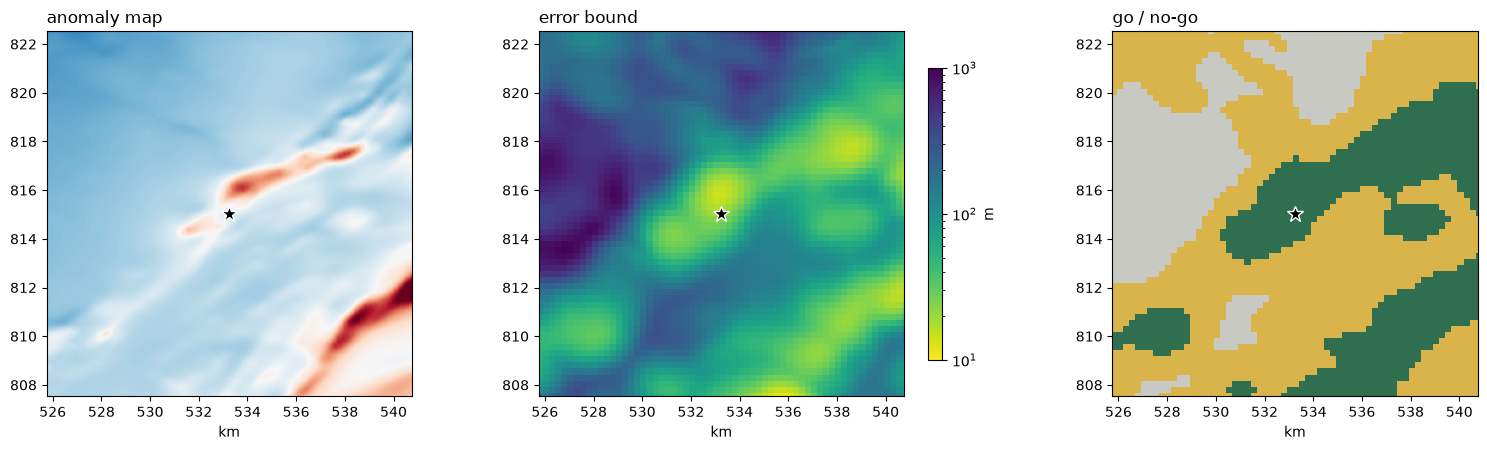

In [3]:
LAT, LON = 54.08, -9.02
BOX_KM = 15

x0, y0 = grid._to_grid.transform(LON, LAT)
half = BOX_KM * 500
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
l, b_, r, t = grid.bounds
ax[0].imshow(grid.values, extent=(km(l), km(r), km(b_), km(t)), cmap="RdBu_r",
             vmin=np.nanpercentile(grid.values, 2), vmax=np.nanpercentile(grid.values, 98))
ax[0].set_title("anomaly map", loc="left")
im = ax[1].imshow(bound, extent=ext, cmap="viridis_r", norm=LogNorm(10, 1000))
fig.colorbar(im, ax=ax[1], shrink=0.8, label="m"); ax[1].set_title("error bound", loc="left")
ax[2].imshow(classes, extent=ext, cmap=class_cmap, vmin=-0.5, vmax=4.5, interpolation="nearest")
ax[2].set_title("go / no-go", loc="left")
for a in ax:
    a.plot(km(x0), km(y0), "k*", ms=12, mec="white")
    a.set_xlim(km(x0 - half), km(x0 + half)); a.set_ylim(km(y0 - half), km(y0 + half))
    a.set_xlabel("km"); a.set_aspect("equal")
fig.tight_layout()

print(f"bound {nav.at(LAT, LON)[0]:.0f} m, class {CLASSES[int(nav.at(LAT, LON, layer=classes)[0])]}, "
      f"map error {nav.at(LAT, LON, layer=nav.map_error_nt())[0]:.1f} nT, "
      f"texture in all directions {nav.at(LAT, LON, layer=nav.anisotropy())[0]:.2f} (1 = all, 0 = a ramp)")

## 3. Does the map predict what the filter does? And does the filter know when it's lost?

The **protection level** is the filter's own warning: 5.33 × its largest uncertainty, the radius it
should essentially never be outside. If the error goes past it, the filter is confidently wrong, which is the dangerous
failure. This runs the real filter (10 min, tactical INS) at one spot per class.

In [4]:
TESTS = {"good (Co. Mayo)": (54.08, -9.02), "marginal": (54.773, -7.444),
         "flat": (52.053, -7.733), "too rough": (53.775, -9.569)}
rows, runs = [], {}
for name, (lat, lon) in TESTS.items():
    run = scenario.simulate(lat, lon, minutes=10, grades=["tactical"]).runs["tactical"]
    runs[name] = run
    pl = run.protection_level_m()
    rows.append({"place": name, "bound (m)": round(nav.at(lat, lon)[0]),
                 "INS only, 10 min (m)": round(run.ins_error_m[-1]),
                 "filter, 10 min (m)": round(run.error_m[-1]),
                 "protection level (m)": round(pl[-1]),
                 "time error > PL": f"{np.mean(run.error_m > pl):.0%}"})
pd.DataFrame(rows).set_index("place")

,bound (m),"INS only, 10 min (m)","filter, 10 min (m)",protection level (m),time error > PL
place,,,,,
good (Co. Mayo),21,231,50,612,0%
marginal,124,231,767,3447,0%
flat,1217,231,1879,6845,0%
too rough,19,231,2924,47,82%


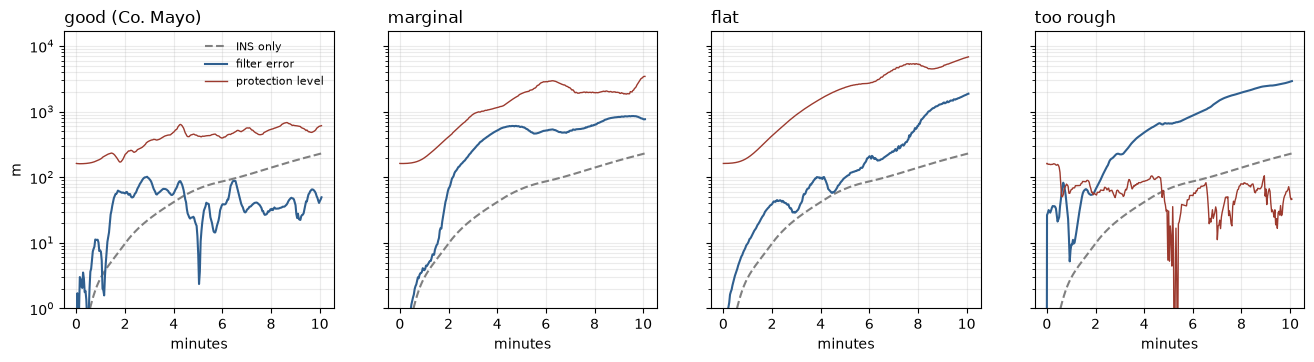

In [5]:
fig, ax = plt.subplots(1, len(runs), figsize=(16, 3.6), sharey=True)
for a, (name, run) in zip(ax, runs.items()):
    el = run.elapsed_s / 60
    a.semilogy(el, run.ins_error_m, "--", color="0.5", label="INS only")
    a.semilogy(el, run.error_m, color="#2f5f8f", label="filter error")
    a.semilogy(el, run.protection_level_m(), color="#9c3a2e", lw=1, label="protection level")
    a.set_title(name, loc="left"); a.set_xlabel("minutes"); a.grid(alpha=0.25, which="both")
ax[0].set_ylabel("m"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_ylim(1, None);

## What this says

- **Roughly a fifth of surveyed Ireland is good ground** for this filter, about a third is marginal, and about half is too flat. Under 1% is too rough, mostly the Antrim basalts in the north-east. That's an honest map of where it works and where it doesn't.
- **The protection level is honest everywhere except "too rough".** Over flat or marginal ground the filter can wander, but it *knows*, and its protection level grows to kilometres. Over rough ground it's confidently wrong, which is exactly the case this map flags before take-off.
- **What to do with it:** plan routes through good ground, and fall back to the INS whenever the protection level is bigger than the INS's own expected drift.
- **DCU is not on the national survey.** A flight there has no map to match against (COH-22 / COH-37).
- **Limits:** the bound assumes a filter that has already locked on. It ignores INS drift and look-alike places far apart, and it's computed at the survey's 60 m height. Use it to rank places, not to promise an accuracy.